# CycloPepper Cyclization-Site and Label Consistency Analysis (Phase 3)

**Purpose:** Examine experimental labels within cyclic rotation groups and distinguish label differences among distinct linear precursors from conflicting labels for an identical sequence. This is an observational analysis, not causal evidence of a cyclization-site effect.

**Input:** `CycloPepper_Phase2_All_Results.zip` exported by Phase 2.

**How to run:** Open this notebook in Google Colab, select **Runtime → Run all**, and upload the Phase 2 archive when prompted. No model retraining or GPU is required.

**Output:** `CycloPepper_Phase3_Results.zip` with group summaries, representative records, a label visualization, and saved holdout error analyses.


In [ ]:
import io, zipfile, os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from google.colab import files

print('Upload CycloPepper_Phase2_All_Results.zip:')
uploaded = files.upload()
zipname = next((k for k in uploaded if k.lower().endswith('.zip')), None)
if zipname is None: raise ValueError('Please upload the Phase 2 ZIP file.')
with zipfile.ZipFile(io.BytesIO(uploaded[zipname])) as src:
    book = pd.ExcelFile(io.BytesIO(src.read('CycloPepper_Phase2_Results.xlsx')))
    df = pd.read_excel(book, sheet_name='Cleaned_Data')
    holdout = pd.read_csv(io.BytesIO(src.read('holdout_predictions.csv')))
assert {'Sequence','Score','rotation_group'}.issubset(df.columns)
print('Loaded:',df.shape[0],'records,',df.rotation_group.nunique(),'rotation groups')
display(df.head())

Upload CycloPepper_Phase2_All_Results.zip:


Saving CycloPepper_Phase2_All_Results.zip to CycloPepper_Phase2_All_Results.zip
Loaded: 306 records, 277 rotation groups


,Sequence,Score,rotation_group
0,RG,1,GR
1,HG,1,GH
2,NG,1,GN
3,QG,1,GQ
4,FW,1,FW


## 1. Examine rotation groups and label conflicts

A rotation group contains linear sequences related by cyclic shifts. Distinct linear precursors may correspond to different head-to-tail closure choices. Conflicting labels for an identical sequence cannot be attributed to a different closure site without additional evidence.


In [ ]:
group = df.groupby('rotation_group',as_index=False).agg(
  records=('Score','size'), n_sequences=('Sequence','nunique'),
  n_labels=('Score','nunique'), positives=('Score','sum'))
group['mixed_labels'] = group.n_labels > 1
mixed = group[group.mixed_labels].copy()
identical_conflicts = (df.groupby('Sequence')['Score'].nunique()>1)
conflicting_sequences = identical_conflicts[identical_conflicts].index.tolist()
summary = pd.DataFrame([{
  'Total records':len(df), 'Rotation groups':len(group),
  'Groups with >1 record':int((group.records>1).sum()),
  'Mixed-label rotation groups':len(mixed),
  'Identical sequences with contradictory labels':len(conflicting_sequences)
}])
display(summary)
print('Identical sequences with contradictory labels:',conflicting_sequences)
print('Mixed-label groups with their member sequences:')
for key in mixed.rotation_group:
    print('\n',key)
    display(df.loc[df.rotation_group==key,['Sequence','Score']].reset_index(drop=True))

,Total records,Rotation groups,Groups with >1 record,Mixed-label rotation groups,Identical sequences with contradictory labels
0,306,277,21,8,1


Identical sequences with contradictory labels: ['RS']
Mixed-label groups with their member sequences:

 AACAYRGF


,Sequence,Score
0,FAACAYRG,1
1,YRGFAACA,1
2,CAYRGFAA,0



 AFQAYG


,Sequence,Score
0,AFQAYG,1
1,GAFQAY,0



 DPGTFIL


... (7 outputs left out)


 GH


,Sequence,Score
0,HG,1
1,GH,0



 RS


,Sequence,Score
0,RS,1
1,RS,0


## 2. Visualize observed mixed-label groups

The visualization displays recorded binary experimental labels within cyclic rotation groups. These labels are not measured cyclization yields, and label differences do not by themselves establish why experimental outcomes differed.


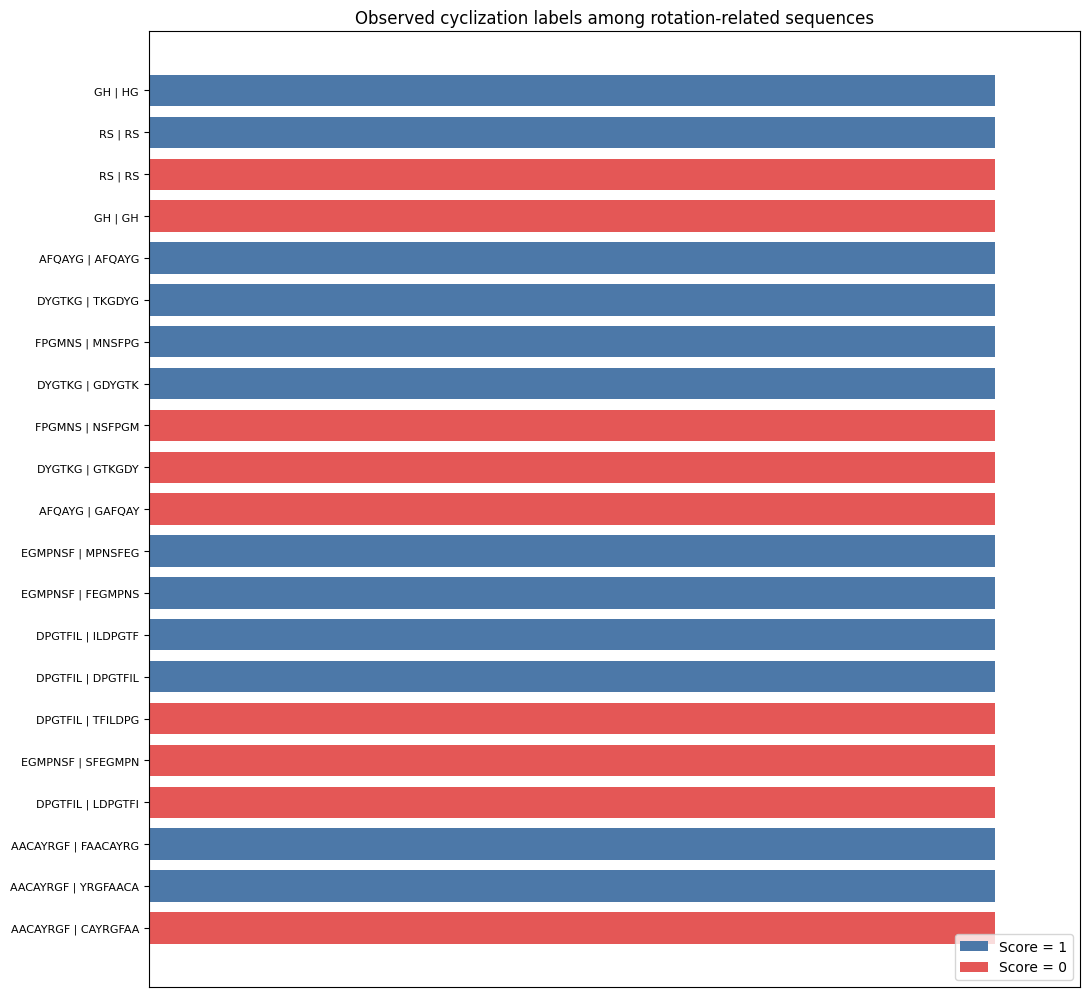

In [ ]:
groups_show = df[df.rotation_group.isin(mixed.rotation_group)].copy()
fig,ax=plt.subplots(figsize=(11,max(4,0.48*len(groups_show))))
labels=[]
for i,(_,r) in enumerate(groups_show.iterrows()):
  ax.barh(i,1,color=('#4C78A8' if int(r.Score)==1 else '#E45756'),height=0.75)
  labels.append(str(r.rotation_group)+' | '+str(r.Sequence))
ax.set_yticks(range(len(labels)),labels=labels,fontsize=8)
ax.set_xlim(0,1.1);ax.set_xticks([])
ax.invert_yaxis();ax.set_title('Observed cyclization labels among rotation-related sequences')
from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor='#4C78A8',label='Score = 1'),Patch(facecolor='#E45756',label='Score = 0')],loc='lower right')
fig.tight_layout()
fig.savefig('phase3_rotation_group_labels.png',dpi=220,bbox_inches='tight')
plt.show()

## 3. Identify representative cases

Select mixed-label groups containing distinct linear sequences, excluding identical-sequence label conflicts from examples of different linear precursors. The observed records alone do not establish matched reaction conditions or causal site effects.


In [ ]:
candidate_keys=[]
for key in mixed.rotation_group:
   rows=df[df.rotation_group==key]
   if rows.Sequence.nunique()>1 and not any(s in conflicting_sequences for s in rows.Sequence):
      candidate_keys.append(key)
case_table=df[df.rotation_group.isin(candidate_keys)][['rotation_group','Sequence','Score']].sort_values(['rotation_group','Sequence'])
print('Candidate mixed-label groups with distinct sequences:',len(candidate_keys))
display(case_table)
case_table.to_csv('phase3_site_case_studies.csv',index=False)
summary.to_csv('phase3_data_quality_summary.csv',index=False)
# Save all flagged groups, including contradictory identical sequences.
groups_show[['rotation_group','Sequence','Score']].to_csv('phase3_all_mixed_groups.csv',index=False)

Candidate mixed-label groups with distinct sequences: 7


,rotation_group,Sequence,Score
272,AACAYRGF,CAYRGFAA,0
257,AACAYRGF,FAACAYRG,1
268,AACAYRGF,YRGFAACA,1
175,AFQAYG,AFQAYG,1
213,AFQAYG,GAFQAY,0
241,DPGTFIL,DPGTFIL,1
240,DPGTFIL,ILDPGTF,1
249,DPGTFIL,LDPGTFI,0
246,DPGTFIL,TFILDPG,0
195,DYGTKG,GDYGTK,1


## 4. Review errors from Phase 2

Analyze the predictions already saved by Phase 2 on its held-out test set. These are not new predictions for every theoretical cyclic rotation.


In [ ]:
holdout['RF_correct']=(holdout.Random_Forest_pred==holdout.Score)
errors=holdout.loc[~holdout.RF_correct].copy()
print('Test records:',len(holdout),'Random Forest errors:',len(errors))
print('False positives:',int(((holdout.Score==0)&(holdout.Random_Forest_pred==1)).sum()))
print('False negatives:',int(((holdout.Score==1)&(holdout.Random_Forest_pred==0)).sum()))
display(errors[['Sequence','Score','Random_Forest_pred','Random_Forest_prob1']].head(20))
errors.to_csv('phase3_rf_errors.csv',index=False)

Test records: 60 Random Forest errors: 21
False positives: 12
False negatives: 9


,Sequence,Score,Random_Forest_pred,Random_Forest_prob1
0,NG,1,0,0.272755
1,FC,1,0,0.352815
2,MY,1,0,0.360116
3,RS,1,0,0.440370
10,GYG,1,0,0.344686
24,ACAY,1,0,0.407526
25,GPTL,1,0,0.462315
27,FQAY,0,1,0.504193
28,TDDA,0,1,0.593182
32,MRPFW,1,0,0.487995


## 5. Export analysis results

Download `CycloPepper_Phase3_Results.zip` for reproducible review. It contains the observed mixed-label group data, candidate case-study sequences, group-level data-quality summary, holdout error records, and a label plot.


In [ ]:
names=['phase3_rotation_group_labels.png','phase3_site_case_studies.csv','phase3_data_quality_summary.csv','phase3_all_mixed_groups.csv','phase3_rf_errors.csv']
with zipfile.ZipFile('CycloPepper_Phase3_Results.zip','w',zipfile.ZIP_DEFLATED) as out:
    for name in names:out.write(name)
files.download('CycloPepper_Phase3_Results.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>